# 1 — Importação das bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

# Reprodutibilidade
np.random.seed(42)
tf.random.set_seed(42)

2 — Definição da função analítica

precisamos implementar a função matemática que será utilizada para gerar os dados.

O NumPy já possui essa operação por meio de np.sinc()

In [2]:
def funcao_analitica(x1, x2):

    soma = x1 + x2

    resultado = (
        (x1**2 + x2**2 + x1*x2) * np.sinc(soma)
        - 0.9
    )

    return resultado

# 3 — Geração do conjunto de dados
Agora vamos gerar 30.000 amostras aleatórias dentro do intervalo estabelecido no enunciado.

Cada amostra terá duas entradas (\(x_1\) e \(x_2\)) e uma saída, que será o resultado da função analítica.

In [3]:
# Quantidade de amostras
N = 30000

# Geração aleatória das entradas
x1 = np.random.uniform(-10, 10, N)
x2 = np.random.uniform(-10, 10, N)

# Organização das entradas
X = np.column_stack((x1, x2))

# Cálculo das saídas pela função analítica
y = funcao_analitica(x1, x2).reshape(-1, 1)

print("Dimensão das entradas:", X.shape)
print("Dimensão das saídas:", y.shape)
print("Valor mínimo da saída:", y.min())
print("Valor máximo da saída:", y.max())

Dimensão das entradas: (30000, 2)
Dimensão das saídas: (30000, 1)
Valor mínimo da saída: -19.928421258791808
Valor máximo da saída: 98.19117907366251


# 4 — Visualização da função analítica

Antes de treinar a rede, vamos visualizar o comportamento da função original em três dimensões.

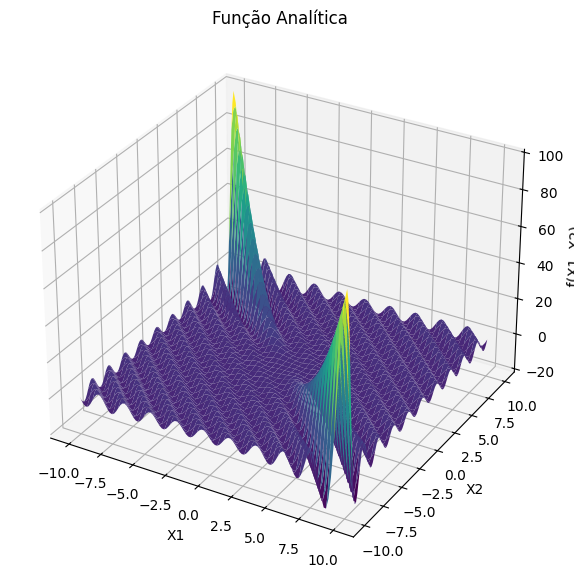

In [4]:
# Criando uma grade de coordenadas
grade = np.linspace(-10, 10, 120)

X1, X2 = np.meshgrid(grade, grade)

# Aplicando a função analítica
Z = funcao_analitica(X1, X2)

# Gráfico tridimensional
fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection='3d')

ax.plot_surface(
    X1, X2, Z,
    cmap='viridis',
    edgecolor='none'
)

ax.set_title('Função Analítica')
ax.set_xlabel('X1')
ax.set_ylabel('X2')
ax.set_zlabel('f(X1, X2)')

plt.show()

# 5 — Separação dos conjuntos de dados


Treinamento	70%	21.000

Validação	15%	4.500

Teste	15%	4.500

In [5]:
# Separação entre treinamento e conjunto temporário
X_treino, X_temp, y_treino, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Divisão do conjunto temporário em validação e teste
X_validacao, X_teste, y_validacao, y_teste = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Treinamento:", X_treino.shape)
print("Validação:", X_validacao.shape)
print("Teste:", X_teste.shape)

Treinamento: (21000, 2)
Validação: (4500, 2)
Teste: (4500, 2)


# 6 — Normalização dos dados
Como os valores das entradas variam entre -10 e +10 e as saídas podem apresentar amplitudes diferentes, vamos normalizar os dados.

Isso ajuda a estabilizar o treinamento e facilita o ajuste dos pesos da rede neural.

In [6]:
# Normalização das entradas
scaler_X = StandardScaler()

X_treino_norm = scaler_X.fit_transform(X_treino)
X_validacao_norm = scaler_X.transform(X_validacao)
X_teste_norm = scaler_X.transform(X_teste)

# Normalização das saídas
scaler_y = StandardScaler()

y_treino_norm = scaler_y.fit_transform(y_treino)
y_validacao_norm = scaler_y.transform(y_validacao)
y_teste_norm = scaler_y.transform(y_teste)

7 — Definição da arquitetura da rede neural


In [7]:
modelo = Sequential([

    # Camada de entrada e primeira camada oculta
    Dense(128, activation='relu', input_shape=(2,)),

    # Demais camadas ocultas
    Dense(128, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),

    # Camada de saída linear pura
    Dense(1, activation='linear')
])

# Configuração do treinamento
modelo.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='mean_squared_error',
    metrics=['mean_squared_error']
)

modelo.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,265 (106.50 KB)

 Trainable params: 27,265 (106.50 KB)

 Non-trainable params: 0 (0.00 B)

# 8 — Treinamento da rede neural
Agora vamos realizar o treinamento utilizando os dados de treinamento e validação.

Também utilizaremos EarlyStopping, que interrompe o treinamento caso o erro de validação deixe de melhorar.

In [8]:
# Interrompe o treinamento quando não houver melhora
parada = EarlyStopping(
    monitor='val_loss',
    patience=25,
    restore_best_weights=True
)

# Treinamento
historico = modelo.fit(
    X_treino_norm,
    y_treino_norm,
    validation_data=(X_validacao_norm, y_validacao_norm),
    epochs=300,
    batch_size=256,
    callbacks=[parada],
    verbose=1
)

print("Treinamento concluído!")
print("Épocas executadas:", len(historico.history['loss']))

Epoch 1/300
83/83 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.8161 - mean_squared_error: 0.8161 - val_loss: 0.7908 - val_mean_squared_error: 0.7908
Epoch 2/300
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.5769 - mean_squared_error: 0.5769 - val_loss: 0.5283 - val_mean_squared_error: 0.5283
Epoch 3/300
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3441 - mean_squared_error: 0.3441 - val_loss: 0.2723 - val_mean_squared_error: 0.2723
Epoch 4/300
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.2060 - mean_squared_error: 0.2060 - val_loss: 0.1684 - val_mean_squared_error: 0.1684
Epoch 5/300
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1278 - mean_squared_error: 0.1278 - val_loss: 0.1411 - val_mean_squared_error: 0.1411
Epoch 6/300
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.1174 - mean_squared_error: 0.1174 - val_loss: 0.1143 - val_mean_squared_error: 0.1143
Epoch 7/300
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0964 - mean_squared_error: 0.0964 - val_loss: 0.1020 - v

9 — Curva da função custo e erro médio quadrático
O enunciado solicita duas curvas:
- Função custo durante o treinamento.
- Erro médio quadrático (MSE) no conjunto de validação.
Como configuramos o MSE como função de custo e também como métrica, podemos visualizar as duas curvas no mesmo gráfico.

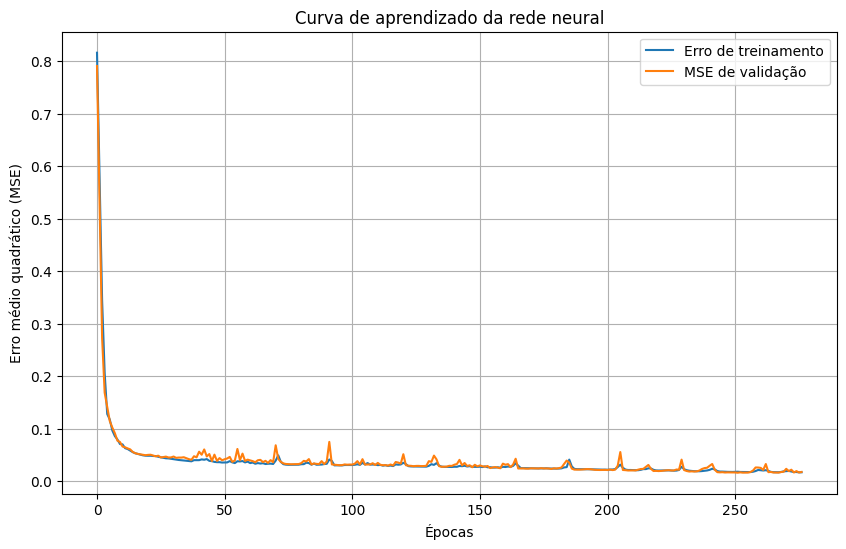

In [12]:
plt.figure(figsize=(10, 6))

plt.plot(
    historico.history['loss'],
    label='Erro de treinamento'
)

plt.plot(
    historico.history['val_mean_squared_error'],
    label='MSE de validação'
)

plt.xlabel('Épocas')
plt.ylabel('Erro médio quadrático (MSE)')
plt.title('Curva de aprendizado da rede neural')

plt.legend()
plt.grid()
plt.show()

# 10 — Comparação entre a função analítica e a função aproximada
Agora vamos verificar se a rede conseguiu aprender a função matemática.

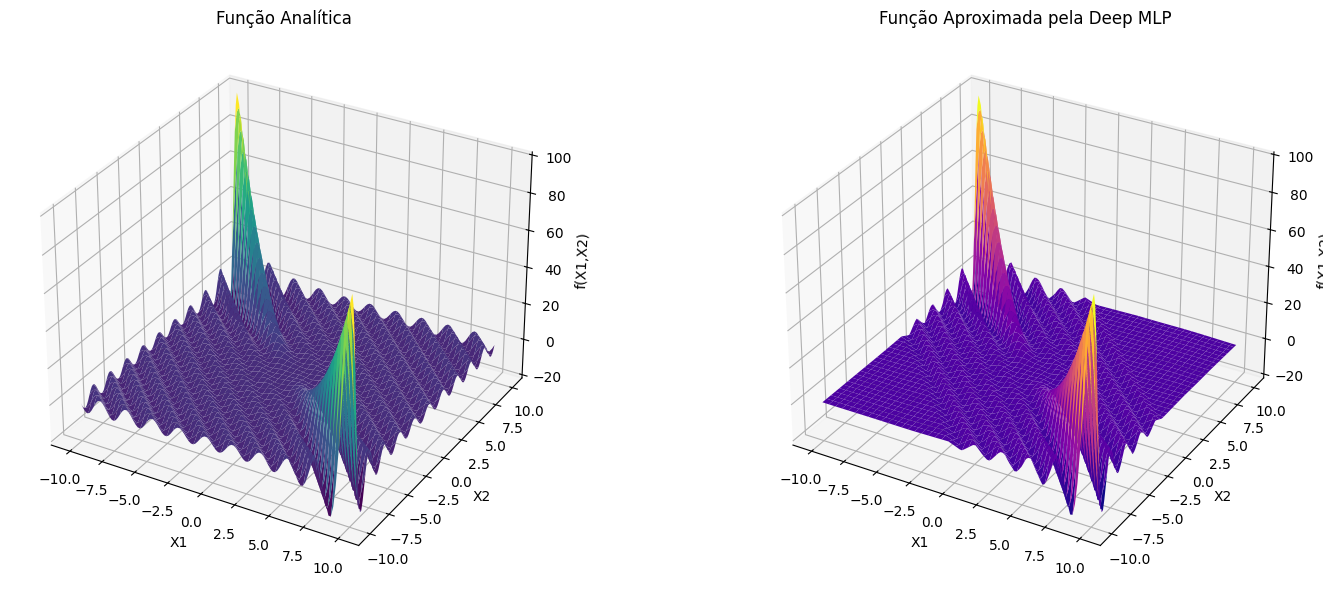

In [13]:
# Criando uma grade para comparação
grade = np.linspace(-10, 10, 120)

X1, X2 = np.meshgrid(grade, grade)

# Valores verdadeiros da função
Z_analitica = funcao_analitica(X1, X2)

# Preparando as entradas para a rede
X_grade = np.column_stack((X1.ravel(), X2.ravel()))

# Normalizando as entradas
X_grade_norm = scaler_X.transform(X_grade)

# Previsão da rede neural
Z_pred_norm = modelo.predict(X_grade_norm, verbose=0)

# Retornando os valores à escala original
Z_aproximada = scaler_y.inverse_transform(
    Z_pred_norm
).reshape(X1.shape)

# Comparação das superfícies
fig = plt.figure(figsize=(16, 6))

# Função original
ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(
    X1, X2, Z_analitica,
    cmap='viridis',
    edgecolor='none'
)
ax1.set_title('Função Analítica')
ax1.set_xlabel('X1')
ax1.set_ylabel('X2')
ax1.set_zlabel('f(X1,X2)')

# Função aproximada
ax2 = fig.add_subplot(122, projection='3d')
ax2.plot_surface(
    X1, X2, Z_aproximada,
    cmap='plasma',
    edgecolor='none'
)
ax2.set_title('Função Aproximada pela Deep MLP')
ax2.set_xlabel('X1')
ax2.set_ylabel('X2')
ax2.set_zlabel('f(X1,X2)')

plt.tight_layout()
plt.show()

# 11 — Avaliação do erro no conjunto de teste
Por fim, vamos calcular o MSE utilizando exclusivamente o conjunto de teste.

MSE no conjunto de teste: 1.5121128667460344


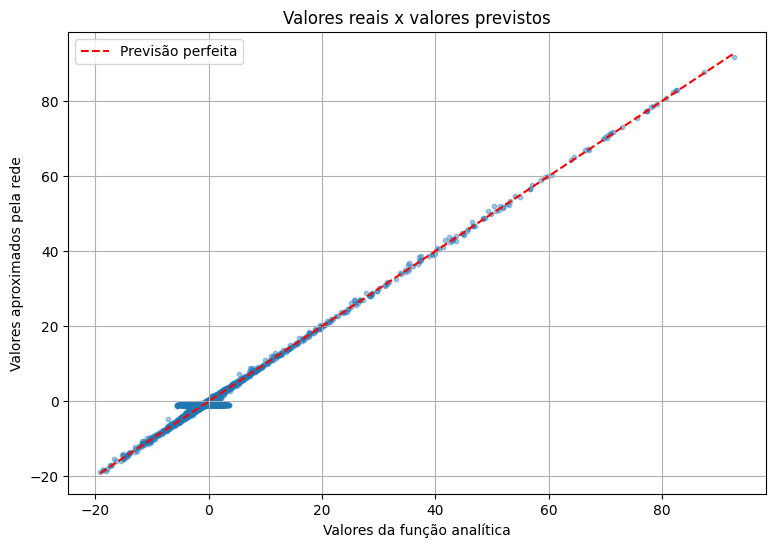

In [14]:
# Previsões da rede neural
y_pred_norm = modelo.predict(X_teste_norm, verbose=0)

# Retornando à escala original
y_pred = scaler_y.inverse_transform(y_pred_norm)

# Cálculo do erro médio quadrático
mse_teste = mean_squared_error(y_teste, y_pred)

print("MSE no conjunto de teste:", mse_teste)

plt.figure(figsize=(9, 6))

plt.scatter(
    y_teste,
    y_pred,
    alpha=0.4,
    s=10
)

limite_min = min(y_teste.min(), y_pred.min())
limite_max = max(y_teste.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    'r--',
    label='Previsão perfeita'
)

plt.xlabel('Valores da função analítica')
plt.ylabel('Valores aproximados pela rede')
plt.title('Valores reais x valores previstos')

plt.legend()
plt.grid()
plt.show()

Neste experimento foi desenvolvida uma rede neural Perceptron de Múltiplas Camadas (MLP) com o objetivo de aproximar uma função analítica de duas variáveis independentes, considerando o intervalo de -10 a +10 para ambas as entradas.

Foram geradas 30.000 amostras, divididas em conjuntos de treinamento, validação e teste. A arquitetura implementada possui duas entradas, quatro camadas ocultas com 128, 128, 64 e 32 neurônios, respectivamente, e uma camada de saída com um neurônio e função de ativação linear.

Durante o treinamento, foi utilizado o algoritmo Adam e o erro médio quadrático (MSE) como função de custo. O desempenho foi acompanhado por meio das curvas de treinamento e validação.

A comparação gráfica entre a função analítica e a função aproximada permite avaliar a capacidade da rede neural de reproduzir o comportamento da expressão matemática. Por fim, o MSE calculado sobre o conjunto de teste fornece uma medida quantitativa do erro de aproximação e da capacidade de generalização do modelo.